In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [2]:
import os
for root, _, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)   

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isna().sum(), "missing")   
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df = df.drop(columns=["customerID"])
df["Churn"] = (df["Churn"] == "Yes").astype(int)

print(df.shape)            
print(df["Churn"].mean())  

(7043, 21)
11 missing
(7043, 20)
0.2653698707936959


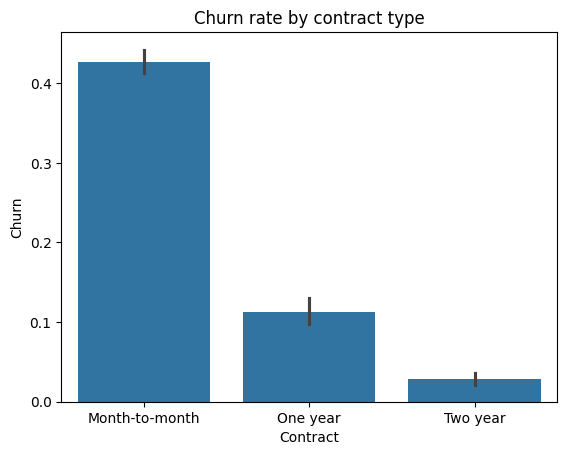

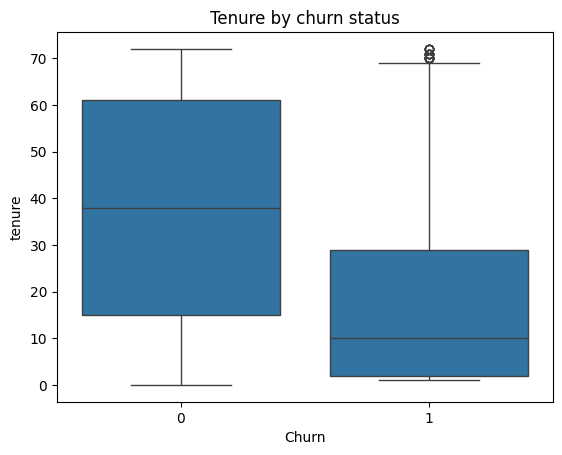

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(data=df, x="Contract", y="Churn")
plt.title("Churn rate by contract type")
plt.show()

sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Tenure by churn status")
plt.savefig("churn_by_contract.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

log_reg = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

log_reg.fit(X_train, y_train)

proba = log_reg.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(classification_report(y_test, pred))
print("ROC-AUC:", roc_auc_score(y_test, proba))

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.841501976284585


                     CV AUC  Test AUC  Precision  Recall     F1
Model                                                          
Logistic Regression   0.845     0.842      0.504   0.783  0.614
Random Forest         0.846     0.842      0.552   0.749  0.636
XGBoost               0.844     0.842      0.512   0.786  0.620


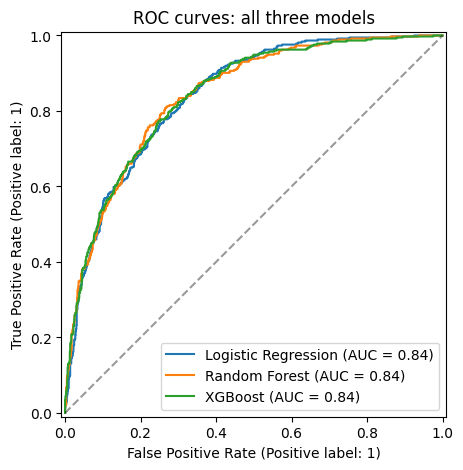

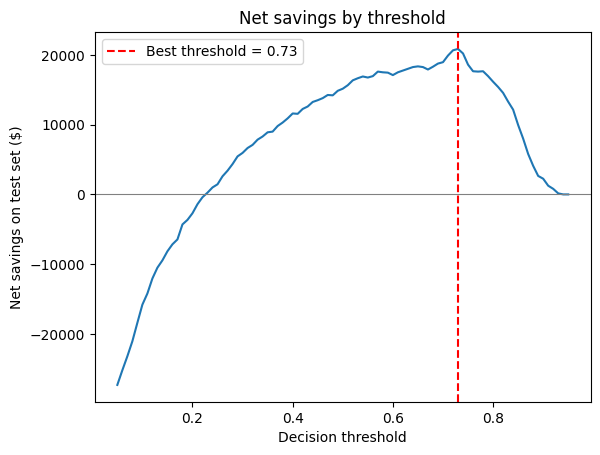

Best threshold: 0.73
Net savings at best threshold: $20,850
Net savings if you contact everyone: $-47,400
Net savings at default 0.5: $15,150


In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import precision_score, recall_score, f1_score
from xgboost import XGBClassifier
import pandas as pd

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=3, learning_rate=0.05,
        scale_pos_weight=neg / pos, eval_metric="logloss", random_state=42
    ),
}

rows = []
fitted = {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=5, scoring="roc_auc").mean()
    pipe.fit(X_train, y_train)
    fitted[name] = pipe

    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({
        "Model": name,
        "CV AUC": round(cv_auc, 3),
        "Test AUC": round(roc_auc_score(y_test, proba), 3),
        "Precision": round(precision_score(y_test, pred), 3),
        "Recall": round(recall_score(y_test, pred), 3),
        "F1": round(f1_score(y_test, pred), 3),
    })

results = pd.DataFrame(rows).set_index("Model")
print(results)

import numpy as np
from sklearn.metrics import RocCurveDisplay

best = fitted["Logistic Regression"]
proba = best.predict_proba(X_test)[:, 1]

# --- ROC curves for all models ---
fig, ax = plt.subplots(figsize=(6, 5))
for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_title("ROC curves: all three models")
plt.savefig("roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Cost-based threshold ---
offer_cost, customer_value, success_rate = 100, 500, 0.5

thresholds = np.linspace(0.05, 0.95, 91)
savings = []
for t in thresholds:
    pred = proba >= t
    tp = (pred & (y_test == 1)).sum()
    fp = (pred & (y_test == 0)).sum()
    savings.append(tp * (success_rate * customer_value - offer_cost) - fp * offer_cost)

savings = np.array(savings)
best_t = thresholds[savings.argmax()]

# Baseline: contact everyone
contact_all = 374 * (success_rate * customer_value - offer_cost) - 1035 * offer_cost

plt.plot(thresholds, savings)
plt.axvline(best_t, color="red", linestyle="--", label=f"Best threshold = {best_t:.2f}")
plt.axhline(0, color="gray", linewidth=0.8)
plt.xlabel("Decision threshold")
plt.ylabel("Net savings on test set ($)")
plt.title("Net savings by threshold")
plt.savefig("savings_curve.png", dpi=150, bbox_inches="tight")
plt.legend()
plt.show()

print(f"Best threshold: {best_t:.2f}")
print(f"Net savings at best threshold: ${savings.max():,.0f}")
print(f"Net savings if you contact everyone: ${contact_all:,.0f}")
print(f"Net savings at default 0.5: ${savings[np.argmin(abs(thresholds - 0.5))]:,.0f}")

Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


0.5 $15,150
0.6 $17,100
0.7 $18,950
0.73 $20,850
0.8 $16,150


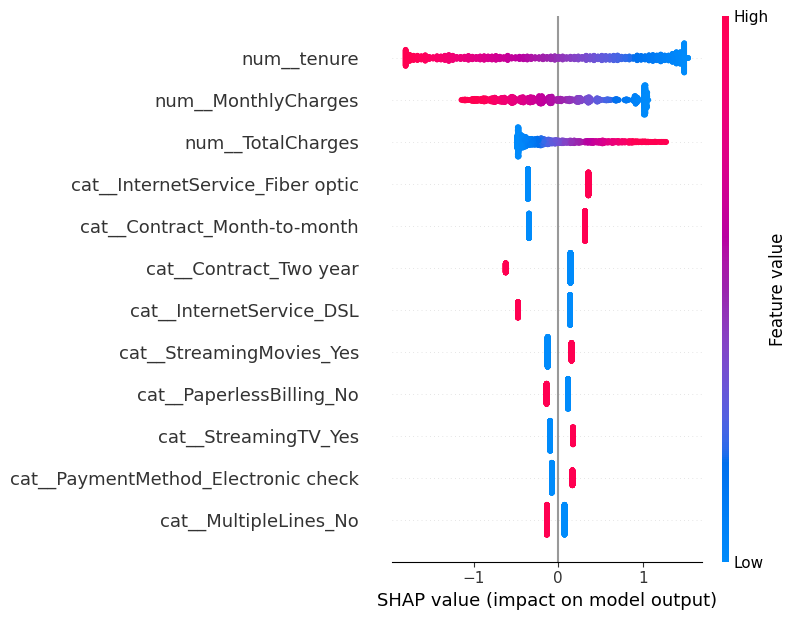

In [7]:
import shap

# Quick robustness check on the threshold
for t in [0.5, 0.6, 0.7, 0.73, 0.8]:
    print(t, f"${savings[np.argmin(abs(thresholds - t))]:,.0f}")

# SHAP on the logistic regression
prep = best.named_steps["prep"]
clf = best.named_steps["clf"]

X_train_t = prep.transform(X_train)
X_test_t = prep.transform(X_test)
if hasattr(X_train_t, "toarray"):
    X_train_t, X_test_t = X_train_t.toarray(), X_test_t.toarray()

feature_names = prep.get_feature_names_out()

explainer = shap.LinearExplainer(clf, X_train_t)
shap_values = explainer.shap_values(X_test_t)

shap.summary_plot(shap_values, X_test_t, feature_names=feature_names, max_display=12, show=False)
plt.savefig("shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
for col in ["InternetService", "PaymentMethod", "PaperlessBilling"]:
    print(df.groupby(col)["Churn"].mean().round(3).sort_values(ascending=False), "\n")

InternetService
Fiber optic    0.419
DSL            0.190
No             0.074
Name: Churn, dtype: float64 

PaymentMethod
Electronic check             0.453
Mailed check                 0.191
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Name: Churn, dtype: float64 

PaperlessBilling
Yes    0.336
No     0.163
Name: Churn, dtype: float64 



In [9]:
import joblib

THRESHOLD = 0.7
risk = pd.DataFrame({"churn_prob": proba}, index=X_test.index)
risk["segment"] = pd.cut(risk["churn_prob"], [0, 0.4, THRESHOLD, 1.0],
                         labels=["Low", "Medium", "High"], include_lowest=True)

print(risk["segment"].value_counts())
print(risk.join(y_test).groupby("segment")["Churn"].mean().round(3))  # actual churn rate per segment

joblib.dump(best, "churn_model.joblib")

segment
Low       715
High      373
Medium    321
Name: count, dtype: int64
segment
Low       0.070
Medium    0.308
High      0.603
Name: Churn, dtype: float64


/tmp/ipykernel_16/1001704101.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(risk.join(y_test).groupby("segment")["Churn"].mean().round(3))  # actual churn rate per segment


['churn_model.joblib']

In [10]:
%%writefile predict.py
import sys
import joblib
import pandas as pd

THRESHOLD = 0.7

def main(csv_path, out_path="predictions.csv"):
    model = joblib.load("churn_model.joblib")
    df = pd.read_csv(csv_path)
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

    ids = df["customerID"] if "customerID" in df else pd.Series(range(len(df)))
    X = df.drop(columns=[c for c in ["customerID", "Churn"] if c in df])

    proba = model.predict_proba(X)[:, 1]
    out = pd.DataFrame({"customerID": ids, "churn_prob": proba.round(3)})
    out["segment"] = pd.cut(proba, [0, 0.4, THRESHOLD, 1.0],
                            labels=["Low", "Medium", "High"], include_lowest=True)
    out.sort_values("churn_prob", ascending=False).to_csv(out_path, index=False)
    print(out["segment"].value_counts())

if __name__ == "__main__":
    main(*sys.argv[1:])

Writing predict.py


In [11]:
!python predict.py /kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv
pd.read_csv("predictions.csv").head()

segment
Low       3598
High      1784
Medium    1661
Name: count, dtype: int64


,customerID,churn_prob,segment
0,9497-QCMMS,0.939,High
1,5178-LMXOP,0.938,High
2,9300-AGZNL,0.938,High
3,2720-WGKHP,0.937,High
4,4424-TKOPW,0.937,High


In [12]:
!pip list 2>/dev/null | grep -iE "^(scikit-learn|pandas|numpy|joblib|shap|seaborn|matplotlib) "

joblib                                1.6.0
matplotlib                            3.10.0
numpy                                 2.1.3
pandas                                2.3.3
scikit-learn                          1.6.1
seaborn                               0.13.2
shap                                  0.54.1


In [13]:
!pip list 2>/dev/null | grep -i xgboos

xgboost                               3.4.1
